# Building the final sample

This notebook applies every cut used in the midplane analysis to the SDSS-V Astra ASPCAP catalog and saves the remaining stars to a file, so later notebooks can load it instead of repeating the cuts.

**Inputs**
- `astraAllStarASPCAP-0.8.0.fits.gz`: SDSS-V Astra ASPCAP catalog

**Output**
- `final_sample_zsun0.fits`: every original catalog column for each star that passes all the cuts, plus computed columns (distance, Galactocentric x, y, z, R, phi, [Mg/Fe] and its uncertainty, and the S/N we used)
- `final_sample_cut_log.csv`: how many stars remain after each cut

**How to read it:** each section below is one stage of cuts, with a short description, the code, and the number of stars left. The chemistry and coordinate cuts use the functions in `src/` (`chemistry.py`, `coords.py`), so they are exactly the cuts used in the analysis. The quality cuts before the chemistry are written out step by step here. We do not cut on radial velocity or proper motion.

In [18]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import astropy.table as at
import astropy.units as u
import astropy.coordinates as coord
from astropy.table import Table
from astropy.coordinates import SkyCoord, Distance

# --- make the midplane package importable ---------------------------------
# This notebook lives in  <repo>/notebooks/  and the code is in  <repo>/src/midplane/
REPO_ROOT = Path.cwd().parent            # folder above notebooks/
sys.path.insert(0, str(REPO_ROOT / "src"))

# helpers and cut definitions from src/midplane/
from midplane.utils import col_to_float_array
from midplane.selection import build_gb_polygon, giant_branch_mask
from midplane.config import SNR_MIN

# --- input and output files -----------------------------------------------
DATA_DIR   = REPO_ROOT / "data"          # CHANGE to the folder holding the two catalog files
ASTRA_FILE = DATA_DIR / "astraAllStarASPCAP-0.8.0.fits.gz"
OUT_SAMPLE = DATA_DIR / "final_sample_zsun0.fits"
OUT_LOG    = DATA_DIR / "final_sample_cut_log.csv"

# --- cut values that are not defined in src/ ------------------------------
FEH_MIN_EXTRA = -0.9     # extra [Fe/H] floor, applied after the src [Fe/H] cut
R_MAX_KPC     = 16.0     # keep stars with Galactocentric R below this

# --- running log of (step, number of stars left) --------------------------
cut_log = []

## 1. Load the catalog and keep one row per star

The parent sample is the Astra ASPCAP catalog. The file can have several rows for the same star, so we keep one row per `sdss_id`. Among the copies we prefer a clean one (not flagged bad, no abundance flags, finite [Fe/H], [Mg/H] and S/N) and, within that, the one with the highest S/N. Rows with no valid `sdss_id` are all kept. In the Astra `snr` column a value of 0 means no measurement, so we treat it as missing.

The checks at the end count how many stars have a usable S/N.

In [19]:
# --- Astra ASPCAP catalog (the parent sample) ---
ASTRA_FILE = DATA_DIR / "astraAllStarASPCAP-0.8.0.fits.gz"     
t = Table.read(ASTRA_FILE, format="fits", hdu=2)               
n_astra = len(t)
cut_log.append(("0a. Astra ASPCAP rows in the file", n_astra))

# --- keep one row per sdss_id: the best usable copy ---
sid = np.ma.filled(t["sdss_id"], -1).astype(np.int64)
valid = sid >= 0

snr_use = col_to_float_array(t, "snr")                         # Astra S/N, no DR17 fallback needed
snr_key = np.where(np.isfinite(snr_use), snr_use, -np.inf)

# a "clean" copy: not flagged bad, no abundance flags, finite [Fe/H], [Mg/H] and S/N
clean = (~np.asarray(t["flag_bad"], bool)
         & (np.asarray(t["fe_h_flags"]) == 0) & (np.asarray(t["mg_h_flags"]) == 0)
         & np.isfinite(col_to_float_array(t, "fe_h"))
         & np.isfinite(col_to_float_array(t, "mg_h"))
         & np.isfinite(snr_use))

# sort by sdss_id, then clean copies first, then highest S/N first
order = np.lexsort((-snr_key, ~clean, sid))
sid_sorted = sid[order]
is_first = np.r_[True, sid_sorted[1:] != sid_sorted[:-1]]
keep = np.sort(order[is_first | ~valid[order]])                # all invalid ids are kept
t = t[keep]
n_parent = len(t)
cut_log.append(("0b. one row per sdss_id (parent catalog)", n_parent))

print(f"Astra rows in the file:                {n_astra:>10,d}")
print(f"After one row per sdss_id (parent):    {n_parent:>10,d}   ({n_parent - n_astra:+,d})")
print(f"  parent rows that are clean copies:   {int(clean[keep].sum()):>10,d}")

# =============================================================================
# CHECK: S/N availability in the new file
# =============================================================================
snr_astra = col_to_float_array(t, "snr")
astra_snr_ok = np.isfinite(snr_astra)
print()
print(f"Stars in the parent catalog:           {n_parent:>10,d}")
print(f"  with an Astra S/N:                   {astra_snr_ok.sum():>10,d}  ({100 * astra_snr_ok.sum() / n_parent:.1f}%)")
print(f"  with no S/N:                         {(~astra_snr_ok).sum():>10,d}")

Astra rows in the file:                 2,408,246
After one row per sdss_id (parent):     2,199,959   (-208,287)
  parent rows that are clean copies:    1,713,851

Stars in the parent catalog:            2,199,959
  with an Astra S/N:                    2,199,931  (100.0%)
  with no S/N:                                 28


In [21]:
# =============================================================================
# CHECK: is the S/N column complete and sensible?
# =============================================================================
raw = t["snr"]
n = len(raw)

is_masked = np.ma.getmaskarray(raw)
vals = np.ma.filled(raw, np.nan).astype(float)

n_masked = int(is_masked.sum())
n_nan    = int((np.isnan(vals) & ~is_masked).sum())
n_inf    = int(np.isinf(vals).sum())
n_zero   = int((vals == 0).sum())
n_neg    = int((vals < 0).sum())
good     = np.isfinite(vals) & (vals > 0)

print(f"S/N column dtype:                      {raw.dtype}")
print(f"Rows:                                  {n:>10,d}")
print(f"  masked (missing):                    {n_masked:>10,d}")
print(f"  NaN:                                 {n_nan:>10,d}")
print(f"  inf:                                 {n_inf:>10,d}")
print(f"  exactly 0:                           {n_zero:>10,d}")
print(f"  negative:                            {n_neg:>10,d}")
print(f"  finite and > 0 (usable):             {int(good.sum()):>10,d}  ({100 * good.sum() / n:.2f}%)")
print()
print(f"S/N of usable rows: min {vals[good].min():.1f}, "
      f"median {np.median(vals[good]):.1f}, max {vals[good].max():.1f}")
print(f"  rows below S/N = 70:                 {int((vals[good] < 20).sum()):>10,d}")

S/N column dtype:                      >f4
Rows:                                   2,199,959
  masked (missing):                            28
  NaN:                                          0
  inf:                                          0
  exactly 0:                               55,606
  negative:                                     0
  finite and > 0 (usable):              2,144,325  (97.47%)

S/N of usable rows: min 0.0, median 111.9, max 5814.5
  rows below S/N = 70:                     39,314


## 2. Quality cuts (before the chemistry)

These cuts remove stars with unreliable spectra, parameters or distances, and select red giants. They are applied one after another, and the count after each is printed and saved to the log. We do not cut on radial velocity or proper motion.

| # | Cut | What it does |
|---|-----|--------------|
| 1 | Finite values | Teff, logg, [Fe/H], [Mg/H] and S/N must all be finite. |
| 2 | Giant branch | (Teff, logg) must lie inside the red giant branch polygon, with Teff 3000 to 7500 K and logg between -2 and 6.5. |
| 3 | S/N | Spectral S/N > 20, from the Astra `snr` column. A value of 0 means no measurement and is treated as missing. |
| 4 | `flag_bad` | The ASPCAP `flag_bad` flag must not be set. In Astra it is built from the ASPCAP `result_flags` and is set if the fit shows any sign of failure or unreliability (suspicious or unphysical parameters, high reduced chi-squared, high v sin i or microturbulence, a parameter at the model grid edge, a failed FERRE fit, low S/N, or a spectrum read error). It is the closest analogue of the DR17 `STAR_BAD` flag. |
| 5 | Abundance flags | `fe_h_flags` = 0 and `mg_h_flags` = 0: no censoring, grid-edge or Teff warning flags on [Fe/H] or [Mg/H]. |
| 6 | Cluster members | `sdss4_apogee_member_flags` = 0: no "likely member of a globular or open cluster" bit is set. These flags come from the SDSS-IV APOGEE reduction. |
| 7 | Parallax | ZGR parallax (`zgr_plx`) must be finite and positive. Distance is 1 / parallax. There is no parallax S/N cut. |
| 8 | ZGR quality | `zgr_quality_flags` < 8 (Zhang, Green & Rix 2023, the recommended basic reliability cut). This removes poor SED fits, stars unlikely under the model prior, and stars whose ZGR parallax disagrees with Gaia DR3 by more than 10 sigma. |
| 9 | Sky position | `ra` and `dec` must be finite, since they are needed to compute a position. |

In [24]:
ZGR_QUALITY_MAX = 8      # keep zgr_quality_flags < 8

def apply_cut(table, mask, label):
    """Keep the rows where mask is True, record the count, and print one line."""
    out = table[np.asarray(mask, bool)]
    cut_log.append((label, len(out)))
    print(f"{label:<56s} {len(out):>10,d}  ({len(out) - len(table):+,d})")
    return out

print(f"{'cut':<56s} {'stars left':>10s}  (removed)")
print(f"{'start: parent catalog':<56s} {len(t):>10,d}")

t_sel = t

# 1. finite values -----------------------------------------------------------
teff = col_to_float_array(t_sel, "teff")
logg = col_to_float_array(t_sel, "logg")
feh  = col_to_float_array(t_sel, "fe_h")
mgh  = col_to_float_array(t_sel, "mg_h")
snr  = col_to_float_array(t_sel, "snr")
snr  = np.where(snr > 0, snr, np.nan)         
t_sel = apply_cut(t_sel,
    np.isfinite(teff) & np.isfinite(logg) & np.isfinite(feh) & np.isfinite(mgh) & np.isfinite(snr),
    "1. finite Teff, logg, [Fe/H], [Mg/H], S/N")

# 2. giant branch ------------------------------------------------------------
teff = col_to_float_array(t_sel, "teff")
logg = col_to_float_array(t_sel, "logg")
t_sel = apply_cut(t_sel, giant_branch_mask(teff, logg, build_gb_polygon()),
    "2. giant branch polygon")

# 3. signal to noise ---------------------------------------------------------
snr = col_to_float_array(t_sel, "snr")
snr = np.where(snr > 0, snr, np.nan)
t_sel = apply_cut(t_sel, snr > SNR_MIN, f"3. S/N > {SNR_MIN}")

# 4. flag_bad ----------------------------------------------------------------
t_sel = apply_cut(t_sel, ~np.asarray(t_sel["flag_bad"], bool), "4. flag_bad not set")

# 5. abundance flags ---------------------------------------------------------
t_sel = apply_cut(t_sel,
    (np.asarray(t_sel["fe_h_flags"]) == 0) & (np.asarray(t_sel["mg_h_flags"]) == 0),
    "5. fe_h_flags == 0 and mg_h_flags == 0")

# 6. cluster members ---------------------------------------------------------
t_sel = apply_cut(t_sel,
    np.asarray(t_sel["sdss4_apogee_member_flags"], dtype=np.int64) == 0,
    "6. not a flagged cluster member")

# 7. parallax ----------------------------------------------------------------
plx = col_to_float_array(t_sel, "zgr_plx")
t_sel = apply_cut(t_sel, np.isfinite(plx) & (plx > 0), "7. zgr_plx finite and > 0")

# 8. ZGR quality -------------------------------------------------------------
t_sel = apply_cut(t_sel,
    np.asarray(t_sel["zgr_quality_flags"], dtype=np.int64) < ZGR_QUALITY_MAX,
    f"8. zgr_quality_flags < {ZGR_QUALITY_MAX}")

# 9. sky position ------------------------------------------------------------
t_sel = apply_cut(t_sel,
    np.isfinite(col_to_float_array(t_sel, "ra")) & np.isfinite(col_to_float_array(t_sel, "dec")),
    "9. finite ra, dec")

print(f"\nstars after the quality cuts: {len(t_sel):,}")

cut                                                      stars left  (removed)
start: parent catalog                                     2,199,959
1. finite Teff, logg, [Fe/H], [Mg/H], S/N                 1,979,375  (-220,584)
2. giant branch polygon                                   1,363,484  (-615,891)
3. S/N > 20                                               1,352,924  (-10,560)
4. flag_bad not set                                       1,320,338  (-32,586)
5. fe_h_flags == 0 and mg_h_flags == 0                    1,317,579  (-2,759)
6. not a flagged cluster member                           1,314,783  (-2,796)
7. zgr_plx finite and > 0                                 1,147,701  (-167,082)
8. zgr_quality_flags < 8                                    546,675  (-601,026)
9. finite ra, dec                                           546,675  (+0)

stars after the quality cuts: 546,675


## 3. Chemistry cuts

**3a. Low-alpha disk.** We keep stars whose [Mg/Fe] is below a two-piece straight line in ([Fe/H], [Mg/Fe]). For [Fe/H] >= -0.1 the line is [Mg/Fe] = -0.05 [Fe/H] + 0.10, and for [Fe/H] < -0.1 it is [Mg/Fe] = -0.20 [Fe/H] + 0.085. The two pieces meet at [Fe/H] = -0.1. Stars with non-finite [Fe/H] or [Mg/Fe] are dropped.

**3b. Metallicity floor from the analysis code.** [Fe/H] >= -1.2.

**3c. Extra metallicity floor.** [Fe/H] > -0.9. This is tighter than 3b, so it is the effective floor of the sample.

In [25]:
from midplane.chemistry import apply_low_alpha_cut, FEH_CUT     # FEH_CUT = -1.2

print(f"{'cut':<56s} {'stars left':>10s}  (removed)")
print(f"{'start: after the quality cuts':<56s} {len(t_sel):>10,d}")

# 3a. low-alpha disk (feh_cut = -inf so only the dividing line is applied here)
low = apply_low_alpha_cut(t_sel, feh_cut=-np.inf)
n_before = len(t_sel)
t_sel = low["table"]
fe = np.asarray(low["fe"])                  # [Fe/H] of the stars we kept, same order as t_sel
cut_log.append(("10. low-alpha ([Mg/Fe] below the dividing line)", len(t_sel)))
print(f"{'10. low-alpha ([Mg/Fe] below the dividing line)':<56s} {len(t_sel):>10,d}  ({len(t_sel) - n_before:+,d})")

# 3b. metallicity floor from the analysis code
keep = fe >= FEH_CUT
t_sel = apply_cut(t_sel, keep, f"11. [Fe/H] >= {FEH_CUT}")
fe = fe[keep]

# 3c. extra metallicity floor (the effective one)
keep = fe > FEH_MIN_EXTRA
t_sel = apply_cut(t_sel, keep, f"12. [Fe/H] > {FEH_MIN_EXTRA}")
fe = fe[keep]

print(f"\nstars after the chemistry cuts: {len(t_sel):,}")
print(f"[Fe/H] range of the sample: {fe.min():.2f} to {fe.max():.2f}")

cut                                                      stars left  (removed)
start: after the quality cuts                               546,675
10. low-alpha ([Mg/Fe] below the dividing line)             418,350  (-128,325)
11. [Fe/H] >= -1.2                                          410,533  (-7,817)
12. [Fe/H] > -0.9                                           404,059  (-6,474)

stars after the chemistry cuts: 404,059
[Fe/H] range of the sample: -0.90 to 0.76


## 4. [Al/Fe] vs [Mg/Mn] polygon

We keep stars that lie inside a four-sided polygon in the ([Al/Fe], [Mg/Mn]) plane, where [Al/Fe] = [Al/H] - [Fe/H] and [Mg/Mn] = [Mg/H] - [Mn/H]. Stars with a non-finite value of either quantity are dropped.

Polygon vertices ([Al/Fe], [Mg/Mn]): (-0.4, -0.25), (0.15, -0.40), (0.6, 0.7), (-0.2, 0.7).

In [26]:
from midplane.chemistry import apply_alfe_mgmn_polygon_cut

n_before = len(t_sel)
t_final, poly_diag, poly_arrays = apply_alfe_mgmn_polygon_cut(t_sel)

cut_log.append(("13. inside the [Al/Fe]-[Mg/Mn] polygon", len(t_final)))
print(f"{'13. inside the [Al/Fe]-[Mg/Mn] polygon':<56s} {len(t_final):>10,d}  ({len(t_final) - n_before:+,d})")
print(f"\nstars with finite [Al/Fe] and [Mg/Mn]: {poly_diag['finite_points']:,} of {poly_diag['input_size']:,}")
print(f"fraction of those inside the polygon:  {poly_diag['inside_fraction_finite']:.3f}")
print(f"stars after the polygon cut: {len(t_final):,}")

13. inside the [Al/Fe]-[Mg/Mn] polygon                      345,537  (-58,522)

stars with finite [Al/Fe] and [Mg/Mn]: 389,237 of 404,059
fraction of those inside the polygon:  0.888
stars after the polygon cut: 345,537


## 5. Computed columns (no stars removed)

We add the following columns to the table for every star. Nothing is cut here, including no cut on radius.

| Column | Meaning |
|---|---|
| `dist_kpc` | Distance in kpc, 1 / ZGR parallax |
| `x_gc_kpc`, `y_gc_kpc`, `z_gc_kpc` | Galactocentric Cartesian position in kpc |
| `R_gc_kpc` | Cylindrical radius, sqrt(x² + y²) |
| `phi_gc_rad` | Azimuth, arctan2(y, x), in radians |
| `mgfe` | [Mg/Fe] = [Mg/H] - [Fe/H] |
| `mgfe_err` | Uncertainty on [Mg/Fe], sqrt(e_mg_h² + e_fe_h²). It is NaN where either error is missing. |
| `alfe`, `mgmn` | [Al/Fe] and [Mg/Mn], the quantities used in the polygon cut |
| `snr_used` | The Astra `snr` used in the S/N cut. A value of 0 in the catalog means no measurement, so it is set to NaN here. |

The Galactocentric frame has the Sun at 8.275 kpc from the Galactic centre and exactly on the midplane (z_sun = 0). Only positions are computed, so proper motions and radial velocities are not needed.

In [27]:
GALCEN_DISTANCE_KPC = 8.275
GALCEN_V_SUN = (8, 254, 8)        # km/s (only defines the frame; no velocities are used)

new_cols = ["dist_kpc", "x_gc_kpc", "y_gc_kpc", "z_gc_kpc", "R_gc_kpc", "phi_gc_rad",
            "mgfe", "mgfe_err", "alfe", "mgmn", "snr_used"]
clash = [c for c in new_cols if c in t_final.colnames]
assert not clash, f"these column names already exist: {clash}"

# --- positions ---
plx = col_to_float_array(t_final, "zgr_plx")                # mas
dist_kpc = 1.0 / plx                                         # kpc
c = SkyCoord(ra=col_to_float_array(t_final, "ra") * u.deg,
             dec=col_to_float_array(t_final, "dec") * u.deg,
             distance=Distance(dist_kpc * u.kpc))
frame = coord.Galactocentric(galcen_distance=GALCEN_DISTANCE_KPC * u.kpc,
                             galcen_v_sun=list(GALCEN_V_SUN) * u.km / u.s,
                             z_sun=0 * u.pc)
gc = c.transform_to(frame)
x, y, z = (gc.x.to_value(u.kpc), gc.y.to_value(u.kpc), gc.z.to_value(u.kpc))

t_final["dist_kpc"]   = dist_kpc
t_final["x_gc_kpc"]   = x
t_final["y_gc_kpc"]   = y
t_final["z_gc_kpc"]   = z
t_final["R_gc_kpc"]   = np.sqrt(x**2 + y**2)
t_final["phi_gc_rad"] = np.arctan2(y, x)

# --- chemistry ---
feh = col_to_float_array(t_final, "fe_h")
mgh = col_to_float_array(t_final, "mg_h")
t_final["mgfe"]     = mgh - feh
t_final["mgfe_err"] = np.sqrt(col_to_float_array(t_final, "e_mg_h")**2
                              + col_to_float_array(t_final, "e_fe_h")**2)
t_final["alfe"] = col_to_float_array(t_final, "al_h") - feh
t_final["mgmn"] = mgh - col_to_float_array(t_final, "mn_h")

# --- S/N used (Astra S/N; 0 means no measurement) ---
snr = col_to_float_array(t_final, "snr")
t_final["snr_used"] = np.where(snr > 0, snr, np.nan)

# --- units ---
for name in ["dist_kpc", "x_gc_kpc", "y_gc_kpc", "z_gc_kpc", "R_gc_kpc"]:
    t_final[name].unit = u.kpc
t_final["phi_gc_rad"].unit = u.rad

# --- summary (nothing is cut here) ---
print(f"stars: {len(t_final):,}   (unchanged)")
for name in ["dist_kpc", "R_gc_kpc", "z_gc_kpc", "mgfe", "mgfe_err", "snr_used"]:
    v = np.asarray(t_final[name], float)
    print(f"{name:<10s} finite: {np.isfinite(v).sum():>8,d}   "
          f"min {np.nanmin(v):8.3f}   median {np.nanmedian(v):8.3f}   max {np.nanmax(v):8.3f}")

stars: 345,537   (unchanged)
dist_kpc   finite:  345,537   min    0.075   median    2.123   max   36.916
R_gc_kpc   finite:  345,537   min    0.058   median    9.048   max   33.385
z_gc_kpc   finite:  345,537   min  -20.905   median   -0.007   max   12.926
mgfe       finite:  345,537   min   -0.424   median    0.010   max    0.260
mgfe_err   finite:  335,927   min    0.002   median    0.005   max    0.051
snr_used   finite:  345,537   min   20.000   median  133.426   max 3290.690


## 6. Save the sample

Two files are written to `data/`:

- `final_sample_zsun0.fits`: every original catalog column for the stars that passed all the cuts, plus the computed columns from the previous section.
- `final_sample_cut_log.csv`: the number of stars left after each cut.

In [28]:
# --- 1. Cut log: stars remaining after each step -----------------------------
log_df = pd.DataFrame(cut_log, columns=["step", "stars_remaining"])
log_df["stars_removed"] = (-log_df["stars_remaining"].diff()).astype("Int64")
                                      
log_df.to_csv(OUT_LOG, index=False)
print(log_df.to_string(index=False))

# --- 2. Record the cut parameters in the FITS header --------------------------
t_final.meta.update({
    "GCDIST":  GALCEN_DISTANCE_KPC,   # Sun-Galactic centre distance [kpc]
    "ZSUNPC":  0,                     # Sun height above the midplane [pc]
    "SNRMIN":  SNR_MIN,               # spectral S/N cut
    "ZGRQMAX": ZGR_QUALITY_MAX,       # keep zgr_quality_flags below this
    "FEHMIN":  FEH_MIN_EXTRA,         # effective [Fe/H] floor
})

# --- 3. Write the sample ------------------------------------------------------
t_final.write(OUT_SAMPLE, format="fits", overwrite=True)

# --- 4. Reload and check ------------------------------------------------------
check = Table.read(OUT_SAMPLE, format="fits")
assert len(check) == len(t_final), "row count differs after reloading"
assert check.colnames == t_final.colnames, "columns differ after reloading"
assert np.allclose(check["R_gc_kpc"], t_final["R_gc_kpc"], equal_nan=True)

print(f"\nSaved {len(check):,} stars and {len(check.colnames)} columns "
      f"({OUT_SAMPLE.stat().st_size / 1e6:,.0f} MB)")
print(f"  sample:  {OUT_SAMPLE}")
print(f"  cut log: {OUT_LOG}")

                                           step  stars_remaining  stars_removed
              0a. Astra ASPCAP rows in the file          2408246           <NA>
       0b. one row per sdss_id (parent catalog)          2199959         208287
      1. finite Teff, logg, [Fe/H], [Mg/H], S/N          1979375         220584
                        2. giant branch polygon          1363484         615891
                                    3. S/N > 20          1352924          10560
                            4. flag_bad not set          1320338          32586
         5. fe_h_flags == 0 and mg_h_flags == 0          1317579           2759
                6. not a flagged cluster member          1314783           2796
                      7. zgr_plx finite and > 0          1147701         167082
                       8. zgr_quality_flags < 8           546675         601026
                              9. finite ra, dec           546675              0
10. low-alpha ([Mg/Fe] below the dividin

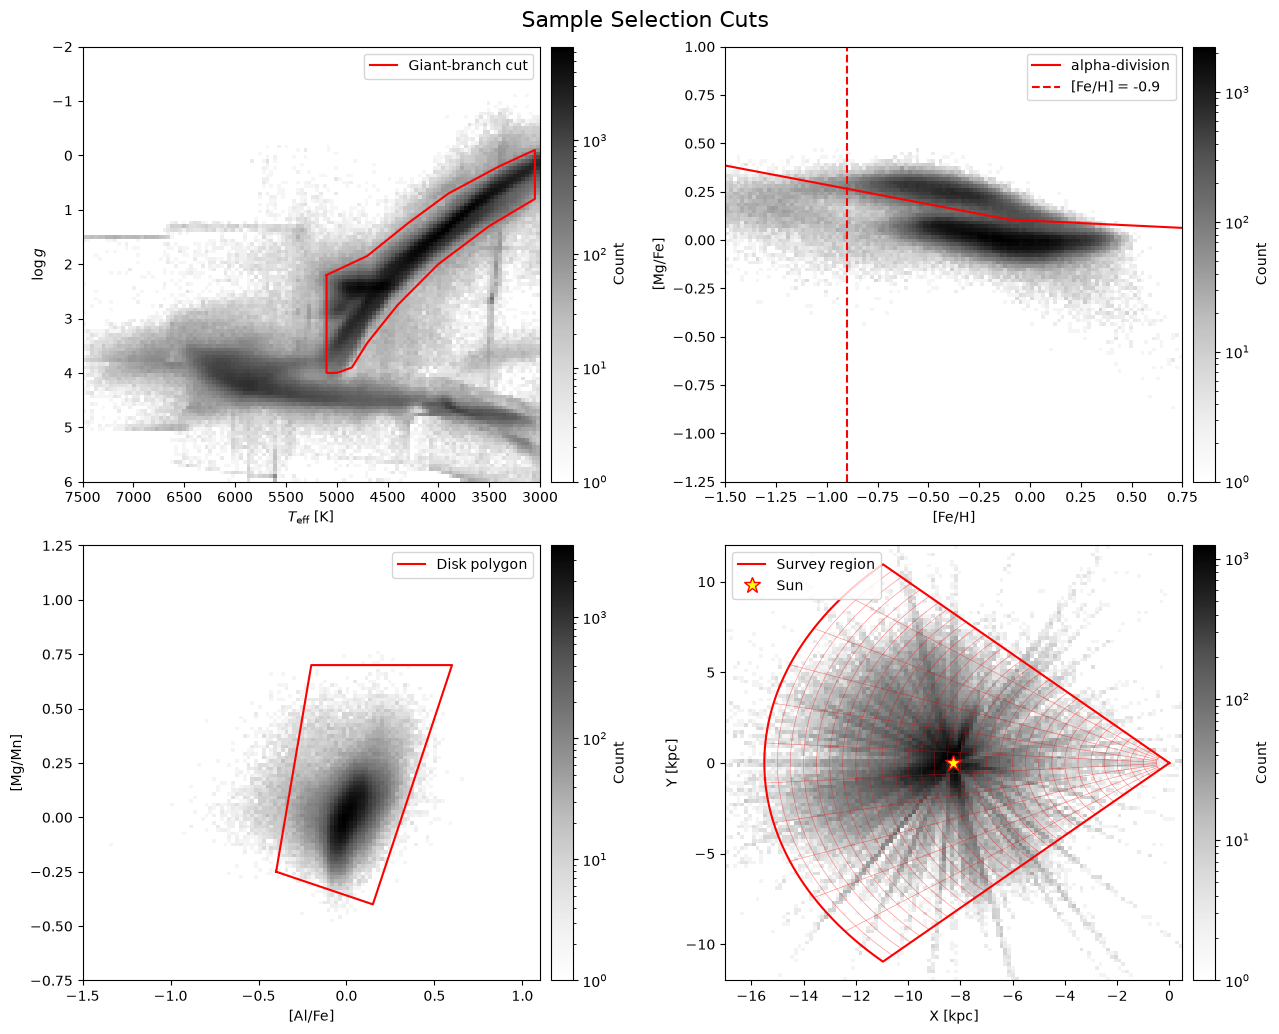

In [30]:
# =============================================================================
# 7. Figure: the cuts (self-contained; uses t, t_sel, t_final from the cells above)
# =============================================================================
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from midplane.config import ALFE_MGMN_POLY_VERTICES
from midplane.chemistry import mgfe_dividing_line

FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

RED  = "red"
CMAP = "Greys"        # white = empty, black = densest

# --- rebuild the stars going into each cut (masks on the parent table t) ------
teff = col_to_float_array(t, "teff")
logg = col_to_float_array(t, "logg")
feh  = col_to_float_array(t, "fe_h")
mgh  = col_to_float_array(t, "mg_h")
snr  = col_to_float_array(t, "snr")
snr  = np.where(snr > 0, snr, np.nan)          

finite = np.isfinite(teff) & np.isfinite(logg) & np.isfinite(feh) & np.isfinite(mgh) & np.isfinite(snr)

plx = col_to_float_array(t, "zgr_plx")
quality = (
    finite
    & giant_branch_mask(teff, logg, build_gb_polygon())
    & (snr > SNR_MIN)
    & ~np.asarray(t["flag_bad"], bool)
    & (np.asarray(t["fe_h_flags"]) == 0) & (np.asarray(t["mg_h_flags"]) == 0)
    & (np.asarray(t["sdss4_apogee_member_flags"], dtype=np.int64) == 0)
    & np.isfinite(plx) & (plx > 0)
    & (np.asarray(t["zgr_quality_flags"], dtype=np.int64) < ZGR_QUALITY_MAX)
    & np.isfinite(col_to_float_array(t, "ra")) & np.isfinite(col_to_float_array(t, "dec"))
)
# check: must match the cut log from section 2
n_expected = dict(cut_log)["9. finite ra, dec"]
assert quality.sum() == n_expected, f"rebuilt {quality.sum():,} stars, log says {n_expected:,}"

# stage arrays for the three panels
teff_a, logg_a = teff[finite], logg[finite]                       # into the giant-branch cut
feh_b, mgfe_b  = feh[quality], mgh[quality] - feh[quality]        # into the alpha cut
alfe_c = col_to_float_array(t_sel, "al_h") - col_to_float_array(t_sel, "fe_h")   # into the polygon cut
mgmn_c = col_to_float_array(t_sel, "mg_h") - col_to_float_array(t_sel, "mn_h")

# --- plotting -----------------------------------------------------------------
def panel(ax, x, y, rng, xlabel, ylabel, bins=120):
    ok = np.isfinite(x) & np.isfinite(y)
    h = ax.hist2d(x[ok], y[ok], bins=bins, range=rng, cmap=CMAP,
                  norm=LogNorm(vmin=1), cmin=1)
    fig.colorbar(h[3], ax=ax, pad=0.02).set_label("Count")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))

# (a) Teff-logg with the giant-branch cut
ax = axes[0, 0]
panel(ax, teff_a, logg_a, [[3000, 7500], [-2, 6]], r"$T_{\rm eff}$ [K]", r"$\log g$")
gb = build_gb_polygon()
ax.plot(gb[:, 0], gb[:, 1], color=RED, lw=1.5, label="Giant-branch cut")
ax.invert_xaxis(); ax.invert_yaxis(); ax.legend(loc="upper right")

# (b) [Fe/H]-[Mg/Fe] with the alpha division and the [Fe/H] floor
ax = axes[0, 1]
panel(ax, feh_b, mgfe_b, [[-1.5, 0.75], [-1.25, 1.0]], "[Fe/H]", "[Mg/Fe]")
xx = np.linspace(-1.5, 0.75, 300)
ax.plot(xx, mgfe_dividing_line(xx), color=RED, lw=1.5, label="alpha-division")
ax.axvline(FEH_MIN_EXTRA, color=RED, lw=1.5, ls="--", label=f"[Fe/H] = {FEH_MIN_EXTRA}")
ax.legend(loc="upper right")

# (c) [Al/Fe]-[Mg/Mn] with the disk polygon
ax = axes[1, 0]
panel(ax, alfe_c, mgmn_c, [[-1.5, 1.1], [-0.75, 1.25]], "[Al/Fe]", "[Mg/Mn]")
poly = np.vstack([ALFE_MGMN_POLY_VERTICES, ALFE_MGMN_POLY_VERTICES[0]])
ax.plot(poly[:, 0], poly[:, 1], color=RED, lw=1.5, label="Disk polygon")
ax.legend(loc="upper right")

# (d) X-Y of the final sample, with the survey wedge and the radial / azimuthal bins
ax = axes[1, 1]
panel(ax, np.asarray(t_final["x_gc_kpc"], float), np.asarray(t_final["y_gc_kpc"], float),
      [[-17, 0.5], [-12, 12]], "X [kpc]", "Y [kpc]")

R_EDGES = np.arange(0.5, 15.5 + 0.5, 0.5)            # 0.5 kpc annuli
PHI0, HALF_DEG, N_SEG = np.pi, 45.0, 11              # wedge 180 +/- 45 deg, 11 sectors
phi_b = PHI0 - np.deg2rad(HALF_DEG) + np.linspace(0, 2 * np.deg2rad(HALF_DEG), N_SEG + 1)
phi_fine = np.linspace(phi_b[0], phi_b[-1], 200)

for Rb in R_EDGES:                                    # radial bins
    ax.plot(Rb * np.cos(phi_fine), Rb * np.sin(phi_fine), color=RED, lw=0.4, alpha=0.5)
for pb in phi_b:                                      # azimuthal bins
    ax.plot([R_EDGES[0] * np.cos(pb), R_EDGES[-1] * np.cos(pb)],
            [R_EDGES[0] * np.sin(pb), R_EDGES[-1] * np.sin(pb)],
            color=RED, lw=0.4, alpha=0.5)

R_OUT = R_EDGES[-1]                                   # 15.5 kpc, the last bin edge
ax.plot(np.r_[0, R_OUT * np.cos(phi_fine), 0],        # survey wedge outline
        np.r_[0, R_OUT * np.sin(phi_fine), 0],
        color=RED, lw=1.5, label="Survey region")
ax.plot(-GALCEN_DISTANCE_KPC, 0, marker="*", ms=12, mfc="yellow", mec=RED,
        ls="none", label="Sun")
ax.legend(loc="upper left")
fig.suptitle("Sample Selection Cuts", fontsize=16)
plt.tight_layout()
plt.savefig(FIG_DIR / "sample_selection_cuts.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "sample_selection_cuts.png", dpi=300, bbox_inches="tight")
plt.show()